#### ***RAG***
   - ***RAG (Retrieval-Augmented Generation) improves LLM responses by retrieving relevant external knowledge before generating an answer.***
   -  ***A typical pipeline converts documents into embeddings, stores them in a vector database, retrieves the most relevant documents for a user's query, and passes them as context to the LLM.***
   - ***In LangGraph, RAG becomes more robust by using graph-based workflows with conditional routing, retries, document grading, memory, and validation, making it well suited for production Agentic AI applications.***

In [1]:
import warnings
warnings.filterwarnings("ignore")

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.tools import tool
from langgraph.graph import StateGraph,START
from typing import Annotated,TypedDict
from langchain_core.messages import HumanMessage,BaseMessage
from langgraph.prebuilt import ToolNode,tools_condition

from dotenv import load_dotenv
load_dotenv()

True

In [2]:
# Define Our Model
from langchain_mistralai import ChatMistralAI
from langchain_mistralai import MistralAIEmbeddings

llm = ChatMistralAI(
    model="mistral-large-latest",
    temperature=0.3
)

embeddings = MistralAIEmbeddings(
    model="mistral-embed"
)

tokenizer.json:   0%|          | 0.00/1.80M [00:00<?, ?B/s]

In [3]:
loader = PyPDFLoader("../../books/roadmap.pdf")
docs = loader.load()

In [4]:
len(docs)

9

In [5]:
# Text Splitter 
splitter = RecursiveCharacterTextSplitter(chunk_size=1000,chunk_overlap=70)
chunks = splitter.split_documents(docs)

In [6]:
len(chunks)

9

In [7]:
# embeddings = HuggingFaceEmbeddings(
#     model_name="BAAI/bge-small-en-v1.5"
# )
# vector_store = FAISS.from_documents(chunks,embeddings)
# vector_store.save_local("faiss_index")

In [9]:
vector_store = FAISS.from_documents(chunks, embeddings)
vector_store.save_local("faiss_index")

In [10]:
vector_store

In [11]:
retriever = vector_store.as_retriever(search_type="similarity",search_kwargs={'k':3})

In [12]:
response = retriever.invoke("what is roadmap getting agnetic ai jobs")
print(response)

[Document(id='8f914263-c799-4a40-b470-b3f62119c70c', metadata={'producer': 'Skia/PDF m152 Google Docs Renderer', 'creator': 'PyPDF', 'creationdate': '', 'title': 'Agentic AI Interview Process in Big Tech Companies', 'source': '../../books/roadmap.pdf', 'total_pages': 9, 'page': 8, 'page_label': '9'}, page_content='Typical  Agentic  AI  Interview  Rounds  \nRound  Interview  Type  \n1  Recruiter  /  Resume  \n2  Python  +  DSA  \n3  Agentic  AI  Fundamentals  \n4  Live  Agent  Coding  \n5  Agentic  AI  System  Design  \n6  Evaluation  +  Security  \n7  Behavioral  /  Hiring  Manager   \nRecommended  Preparation  \n30%  →  Python  and  DSA   25%  →  Agentic  AI  Fundamentals   25%  →  Agentic  AI  System  Design   10%  →  Evaluation  and  Security   10%  →  Behavioral  Interview'), Document(id='dd8bb0e0-de8c-41f1-8dfc-925233ed6c88', metadata={'producer': 'Skia/PDF m152 Google Docs Renderer', 'creator': 'PyPDF', 'creationdate': '', 'title': 'Agentic AI Interview Process in Big Tech Compan

In [13]:
@tool 
def rag_tool(query:str) -> str:
    """
    - Retrieve relevant information from the PDF document.
    - Use this tool when the user asks factual or conceptual questions.
    - that may be answered using the stored PDF documents.

    - Args:
        query: The question or search query used to retrieve PDF content.
    """
    docs = retriever.invoke(query)
    if not docs:
        return "no relevant result found in provided data."
    formatted_docs = []
    for i,doc in enumerate(docs,start=1):
        source = doc.metadata.get("source","unknown source")
        page = doc.metadata.get("page","unknown page")

        formatted_docs.append(
        f"Document {i}\n"
        f"Source: {source}\n"
        f"Page: {page}\n"
        f"Content: {doc.page_content}")
    return "\n\n".join(formatted_docs)

In [15]:
# Tool Binding
tools = [rag_tool]
llm_tool = llm.bind_tools(tools)

In [16]:
from langgraph.graph.message import add_messages
# Define State 
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [17]:
# Graph Node 
def chat_node(state:ChatState):
    """LLM node that may answer or request a tool call."""
    messages = state['messages']
    response = llm_tool.invoke(messages)
    return {"messages": [response]}

tool_node = ToolNode(tools)

In [18]:
# Graph structure
graph = StateGraph(ChatState)
graph.add_node("chat_node", chat_node)
graph.add_node("tools", tool_node)
graph.add_edge(START, "chat_node")

# If the LLM asked for a tool, go to ToolNode; else finish
graph.add_conditional_edges("chat_node", tools_condition)

graph.add_edge("tools", "chat_node")  
chatbot = graph.compile()

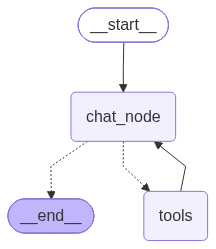

In [19]:
from IPython.display import Image
Image(chatbot.get_graph().draw_mermaid_png())

In [ ]:
# Regular chat
result = chatbot.invoke({"messages": [HumanMessage(content="Hello..!")]})
print(result["messages"][-1].content)

Hello! 😊 How can I assist you today?


In [24]:
# Regular chat
result = chatbot.invoke({"messages": [HumanMessage(content="Using the pdf give me agentic-ai roamdap what skills required to brcome job ready agentic-ai engineer..")]})
print(result["messages"][-1].content)

Here is a **comprehensive roadmap** and the **skills, tools, and technologies** required to become a **job-ready Agentic-AI engineer**:

---

### **1. Core Programming Skills**
#### **Python**
- **Why?** Python is the primary language for AI/ML and Agentic-AI development.
- **Key Topics:**
  - Proficiency in Python syntax and features.
  - Object-Oriented Programming (OOP).
  - Asynchronous programming (asyncio).
  - Working with APIs (REST, GraphQL).
  - Python libraries for AI/ML (e.g., `requests`, `pandas`, `numpy`).

#### **Data Structures and Algorithms (DSA)**
- **Why?** Essential for coding interviews and optimizing Agentic-AI systems.
- **Key Topics:**
  - Arrays, Linked Lists, Stacks, Queues.
  - Trees, Graphs, Hash Tables.
  - Sorting and Searching Algorithms.
  - Dynamic Programming.
  - Big-O Notation and Time Complexity.

---

### **2. Agentic-AI Fundamentals**
#### **Concepts**
- **AI Agents vs Chatbots:**
  - AI agents are autonomous, goal-driven, and can interact with t